Notebook for getting comfortable with all the data and finding the form I want them in for the actual analysis

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import climate_indices as clindices

### Getting to grips with the OPW catchment data

This is from the downoad section of these links for each catchment https://eur05.safelinks.protection.outlook.com/?url=https%3A%2F%2Fwaterlevel.ie%2Fhydro-data%2F%23%2Foverview%2FWaterlevel%2Fstation%2F11628%2FScarriff%2FstationInfo&data=05%7C02%7CCatriona.Duffy%40met.ie%7C20d1cf3bb66f48ca24b308df40958513%7C50f92bd147124111953d7d378a5e8ad0%7C0%7C0%7C639300683145095114%7CUnknown%7CTWFpbGZsb3d8eyJFbXB0eU1hcGkiOnRydWUsIlYiOiIwLjAuMDAwMCIsIlAiOiJXaW4zMiIsIkFOIjoiTWFpbCIsIldUIjoyfQ%3D%3D%7C0%7C%7C%7C&sdata=PGy2MOTaUyKv9udLXSoWkRVxLZxpsbOW%2BYGyZgSfEqs%3D&reserved=0


To do:
Extract just the months leading up to the drought
Delete the rest? If it's easy
Explore it (print time series, see what we're looking at, etc)
Move on to other data sources


In [3]:
scarriff_complete = pd.read_csv('DATA/25030_scarriff_s_complete.csv', header=12)

scarriff_complete.Day = pd.to_datetime(scarriff_complete.Day, format='%d/%m/%Y')

scarriff_complete.head()

# Extract just the months leading up to the drought (not being precise here, just going from Jan)

start_date = pd.Timestamp(year=2018, month=1, day=1)
end_date = pd.Timestamp(year=2018, month=9, day=1)
print(start_date)


date_mask = (scarriff_complete['Day'] > start_date) & (scarriff_complete['Day'] < end_date)

scarriff_data = scarriff_complete[date_mask]
scarriff_data.info()

FileNotFoundError: [Errno 2] No such file or directory: 'DATA/25030_scarriff_s_complete.csv'

In [ ]:
plt.plot(scarriff_data.Day, scarriff_data['Day Min'])
plt.plot(scarriff_data.Day, scarriff_data['Day Max'])
plt.plot(scarriff_data.Day, scarriff_data['Day Mean'])
plt.legend(['Min', 'Max', 'Mean'])
plt.title('Scarriff Waterlevel, OPW data')

### Loading in shape files
That looks pretty good and easy to use, the same website also gives flow and water temp time series. 

Trying to get to grips with shapefiles

In [6]:
catchments = gpd.read_file(
    "DATA/Catchments/2025_FSU_Gauged_Catchment_Boundaries/2025 FSU Gauged Catchment Boundaries/2025 FSU Gauged Catchment Boundaries.shp"
)

# Read in and combine the catchment characteristics CSV from the FSU website with the geopandas catchment boundaries
# TODO: This might mess up the boundaries by converting gpd to pd so double check that. Nope, it doesn't seem to but leaving this here in case of bug later
catchment_descriptors = pd.read_csv("DATA/Catchments/2025+Flood+Studies+Update+(FSU)+Physical+Catchment+Descriptors+(gauged).csv")
catchments = catchments.merge(
    catchment_descriptors,
    on="LOCATION",
    how="left"
)

catchments.head()

,STATION_NU,HA,WATERBODY_x,LOCATION,AREA_KM,AREA_KM_,NODE_ID,DTM_AREA,layer,path,...,Qmedgauged (m^3/s),QMEDgauged - less urban,QMED rural FEMI from PCDs (m3/s),ADJFAC Q (FEMI),HGF (m^3/s),HGF/Qmed,Amax Start,Amax end,Usable Years,Gap (years)
0,01041,01,DEELE,SANDY MILLS,116.180,NaN,NaN,NaN,01041,Z:/WIP_Staff_Folders/RicheMcD/134 FEMI Gauged ...,...,65.450,63.771,47.12,1.353,57.30,0.93,1973.0,2022.0,45.0,5.0
1,01055,01,MOURNE BEG,MOURNE BEG WEIR,9.695,NaN,NaN,NaN,01055,Z:/WIP_Staff_Folders/RicheMcD/134 FEMI Gauged ...,...,2.600,2.600,2.43,1.070,3.80,1.46,1996.0,2022.0,26.0,1.0
2,03051,03,BLACKWATER,FAULKLAND,NaN,143.195,NaN,NaN,03051,Z:/WIP_Staff_Folders/RicheMcD/134 FEMI Gauged ...,...,47.170,42.927,39.97,1.074,34.64,0.73,1975.0,2022.0,43.0,5.0
3,06011,06,FANE,MOYLES MILL,210.594,NaN,NaN,NaN,06011,Z:/WIP_Staff_Folders/RicheMcD/134 FEMI Gauged ...,...,15.902,15.405,13.07,1.179,20.39,1.20,1981.0,2022.0,42.0,0.0
4,06012,06,FANE,CLAREBANE,162.797,NaN,NaN,NaN,06012,Z:/WIP_Staff_Folders/RicheMcD/134 FEMI Gauged ...,...,14.894,14.346,10.66,1.346,17.84,1.20,1957.0,2022.0,66.0,0.0


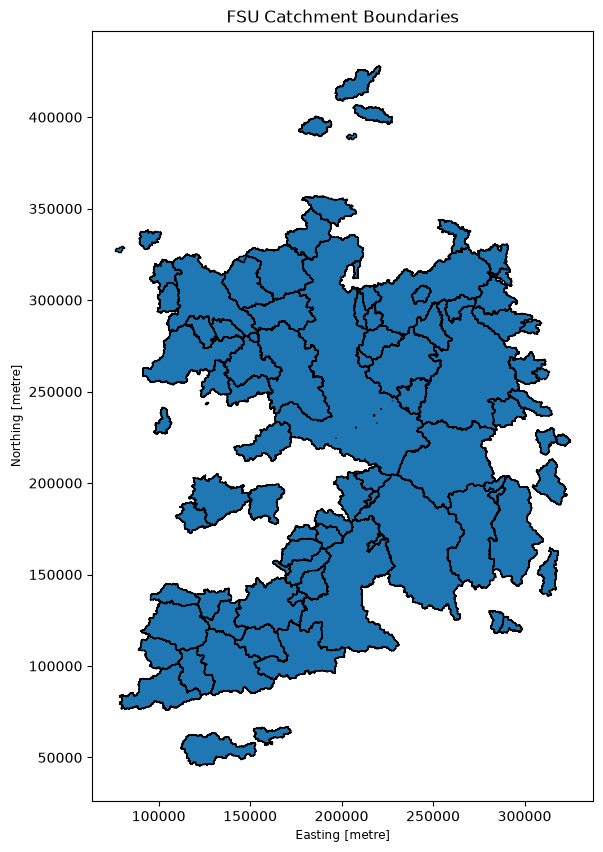

In [7]:
catchments.plot(
    figsize=(10, 10),
    edgecolor="black"
)

plt.title("FSU Catchment Boundaries")
plt.show()

In [8]:
scarriff = catchments[catchments["LOCATION"] == 'SCARRIFF']
curranure = catchments[catchments["LOCATION"] == 'CURRANURE']
ballysadare = catchments[catchments["LOCATION"] == 'BALLYSADARE']
leixlip = catchments[catchments["LOCATION"] == 'LEIXLIP']

### Read in the metoerological data and match it up with catchments

In [9]:
# TODO: I'd like to include 2017 both to have more lead time data and to have a less droughty baseline for comparison
rainfall_2018 = pd.read_csv('DATA/Meteorological/rr_mon_grid_2018.csv')
meantemp_2018 = pd.read_csv('DATA/Meteorological/mmaxtemp_mon_grid_2018.csv')

rainfall_2018.columns = ['east', 'north', 'jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
meantemp_2018.columns = ['east', 'north', 'jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
meantemp_2018.head()

,east,north,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
0,100000,100000,9.32,7.44,8.11,12.52,17.01,21.04,21.25,18.63,15.97,13.38,10.87,11.07
1,100000,101000,9.82,7.84,8.61,12.92,17.49,21.54,21.74,19.02,16.36,13.87,11.47,11.47
2,100000,102000,9.82,7.94,8.61,13.02,17.47,21.54,21.72,19.11,16.46,13.87,11.47,11.57
3,100000,103000,10.12,8.13,8.91,13.22,17.76,21.84,22.00,19.30,16.66,14.07,11.67,11.76
4,100000,104000,10.12,8.23,9.01,13.32,17.75,21.84,21.98,19.39,16.76,14.27,11.77,11.86


In [10]:
print(catchments.crs)

EPSG:29902


In [11]:
# Convert the rainfall coords to geographic points
rainfall_points = gpd.GeoDataFrame(
    rainfall_2018,
    geometry=gpd.points_from_xy(
        rainfall_2018["east"],
        rainfall_2018["north"]
    ),
    crs=catchments.crs)
meantemp_points = gpd.GeoDataFrame(
    meantemp_2018,
    geometry=gpd.points_from_xy(
        meantemp_2018["east"],
        meantemp_2018["north"]
    ),
    crs=catchments.crs)

rainfall_points.head()

,east,north,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec,geometry
0,25000,61000,201.4,102.0,121.8,159.6,91.6,27.7,41.0,75.5,93.4,98.9,240.5,248.4,POINT (25000 61000)
1,25000,96000,178.2,97.0,103.5,126.5,80.7,27.2,51.2,109.9,119.2,88.6,197.0,178.6,POINT (25000 96000)
2,26000,96000,176.9,95.3,102.1,129.8,77.8,29.5,49.0,101.6,114.2,87.4,198.2,180.6,POINT (26000 96000)
3,27000,97000,177.3,97.7,103.6,125.0,80.5,27.7,53.0,113.0,121.6,87.2,196.7,173.4,POINT (27000 97000)
4,27000,100000,187.4,97.2,103.5,135.7,76.3,32.2,46.6,97.4,119.0,90.3,202.5,189.1,POINT (27000 100000)


In [12]:
# Find which grid points fall within a certain catchment
scarriff_rainfall = gpd.sjoin(
    rainfall_points,
    scarriff,
    how="inner",
    predicate="within"
)
scarriff_meantemp = gpd.sjoin(
    meantemp_points,
    scarriff,
    how="inner",
    predicate="within"
)

curranure_rainfall = gpd.sjoin(
    rainfall_points,
    curranure,
    how="inner",
    predicate="within"
)
curranure_meantemp = gpd.sjoin(
    meantemp_points,
    curranure,
    how="inner",
    predicate="within"
)

ballysadare_rainfall = gpd.sjoin(
    rainfall_points,
    ballysadare,
    how="inner",
    predicate="within"
)
ballysadare_meantemp = gpd.sjoin(
    meantemp_points,
    ballysadare,
    how="inner",
    predicate="within"
)

leixlip_rainfall = gpd.sjoin(
    rainfall_points,
    leixlip,
    how="inner",
    predicate="within"
)
leixlip_meantemp = gpd.sjoin(
    meantemp_points,
    leixlip,
    how="inner",
    predicate="within"
)

In [14]:

# Very crude and doesn't account for a lot of the physical reality of the catchment but useful to know
# I'll get the indices working soon
monthly_rainfall_sc = (scarriff_rainfall[['jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']].mean())
monthly_meantemp_sc = (scarriff_meantemp[['jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']].mean())

monthly_rainfall_cu = (curranure_rainfall[['jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']].mean())
monthly_meantemp_cu = (curranure_meantemp[['jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']].mean())

monthly_rainfall_ba = (ballysadare_rainfall[['jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']].mean())
monthly_meantemp_ba = (ballysadare_meantemp[['jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']].mean())

monthly_rainfall_le = (leixlip_rainfall[['jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']].mean())
monthly_meantemp_le = (leixlip_meantemp[['jan', 'feb', 'mar', 'apr' ,'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']].mean())


# What about grid points that cross the boundary? Maybe not ideal but it's probably fine. Could figure out the number of cells
# crossing the boundary for each catchment and see if the effect is roughly equal

#print(monthly_rainfall)

Breaking here for lunch, I think I'm reading all the main data in and it's ready to be put to use

Steps:
- Go through the brief and see if I missed any sources (I'm not using the supplemental stuff yet)
- Plot the catchment + met data I found directly above here as tiem series just out of curiosity
- Read in the temperature and all that from the met eireann source
- Read in the flow and water temp from the OPW source
- Actually do the analysis and calculate the indices and everything
- Then I can get into prediction and all of that
- Maybe have a think about formal EDA stuff I can do quickly and put in the report for completeness

Text(0.5, 1.0, 'Mean monthly mean temp across catchment, 2018')

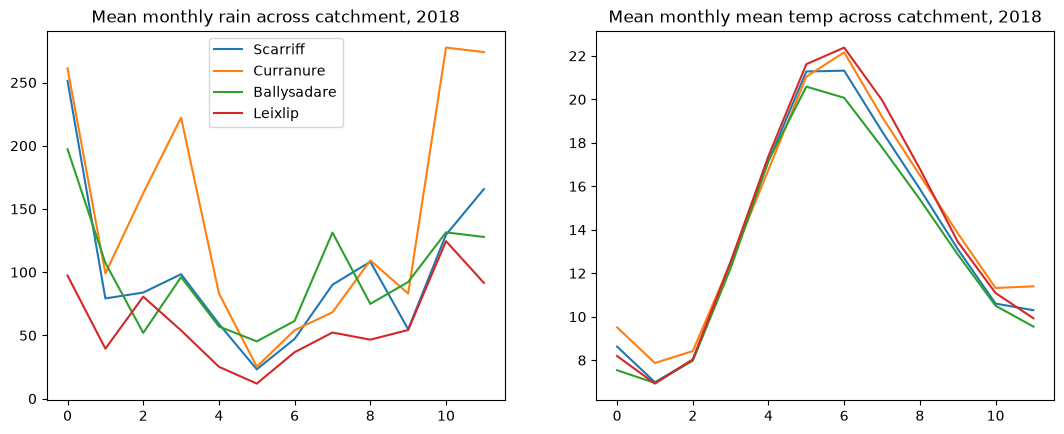

In [15]:
# Plot the combined catchment and met data as time series, could be interesting
fig, ax = plt.subplots(1,2, figsize=(13,4.8))

ax[0].plot(range(0,12), monthly_rainfall_sc, label='Scarriff')
ax[0].plot(range(0,12), monthly_rainfall_cu, label='Curranure')
ax[0].plot(range(0,12), monthly_rainfall_ba, label='Ballysadare')
ax[0].plot(range(0,12), monthly_rainfall_le, label='Leixlip')
ax[0].legend()
ax[0].set_title('Mean monthly rain across catchment, 2018')

ax[1].plot(range(0,12), monthly_meantemp_sc)
ax[1].plot(range(0,12), monthly_meantemp_cu)
ax[1].plot(range(0,12), monthly_meantemp_ba)
ax[1].plot(range(0,12), monthly_meantemp_le)
ax[1].set_title('Mean monthly mean temp across catchment, 2018')


Interesting that Curranure actually had reaonably high rain and still had the drought, I wonder if that will show up in the indices or if the drought there wasn't as bad (or maybe the one wet month wasn't enough to make up for whatever other factors were contributing to the drought there and everywhere else).

Text(0.5, 1.0, 'Met Éireann Grid Points and Catchment Boundaries (Scarriff)')

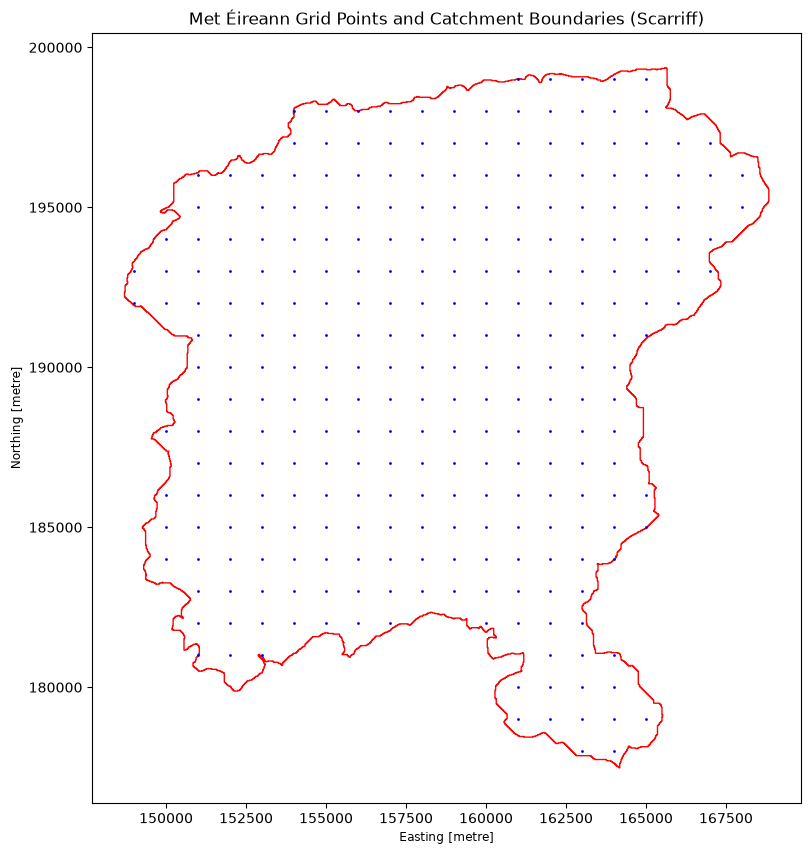

In [18]:
fig, ax = plt.subplots(figsize=(10, 10))

scarriff.plot(
    ax=ax,
    facecolor="none",
    edgecolor="red"
)

#rainfall_points.plot(
scarriff_rainfall.plot(
    ax=ax,
    markersize=1,
    color="blue"
)

plt.title("Met Éireann Grid Points and Catchment Boundaries (Scarriff)")
